Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
       VISIONPORT - END-TO-END SYSTEM ARCHITECTURE

1. SYSTEM CONFIGURATION
-------------------------------------------------------
Python Version: 3.13.18
PyTorch Version: 2.14.1+cpu
GPU Available: False
Hardware: CPU
Execution Device: cpu

2. TENSORRT CONFIGURATION
-------------------------------------------------------
TensorRT Available: False
TensorRT Version: Not installed

3. TRITON CONFIGURATION
-------------------------------------------------------
Triton Client Installed: False
Triton Server Running: False

4. IMAGE ACQUISITION
-------------------------------------------------------
Upload a real photograph...


Saving traffic image.jpg to traffic image.jpg
Image Uploaded Successfully!
Filename: traffic image.jpg

5. YOLOv8 MODEL INITIALIZATION
-------------------------------------------------------
YOLOv8 Model Loaded Successfully!
Model: YOLOv8 Nano
Execution Device: CPU

6. FASTAPI APPLICATION INITIALIZATION
-------------------------------------------------------
FastAPI Application Created Successfully!

7. STARTING FASTAPI SERVER
-------------------------------------------------------
FastAPI Server Started Successfully!
API Address: http://127.0.0.1:8001
Home Endpoint: http://127.0.0.1:8001/
Health Endpoint: http://127.0.0.1:8001/health
Prediction Endpoint: http://127.0.0.1:8001/predict
API Documentation: http://127.0.0.1:8001/docs

8. API HEALTH CHECK
-------------------------------------------------------
API Status: Healthy
Model Loaded: True
Hardware: CPU

9. HTTP POST IMAGE INFERENCE
-------------------------------------------------------
API Response Received Successfully!
Status: 

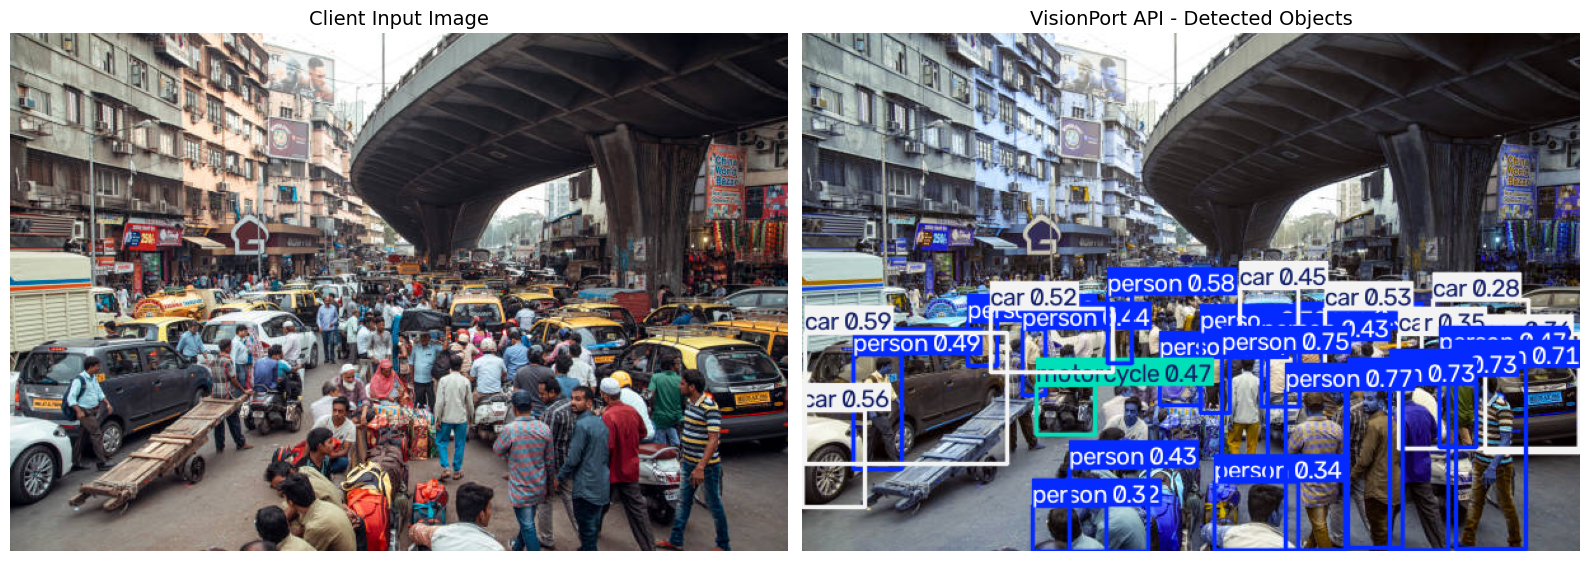


12. SYSTEM ARCHITECTURE VISUALIZATION
-------------------------------------------------------


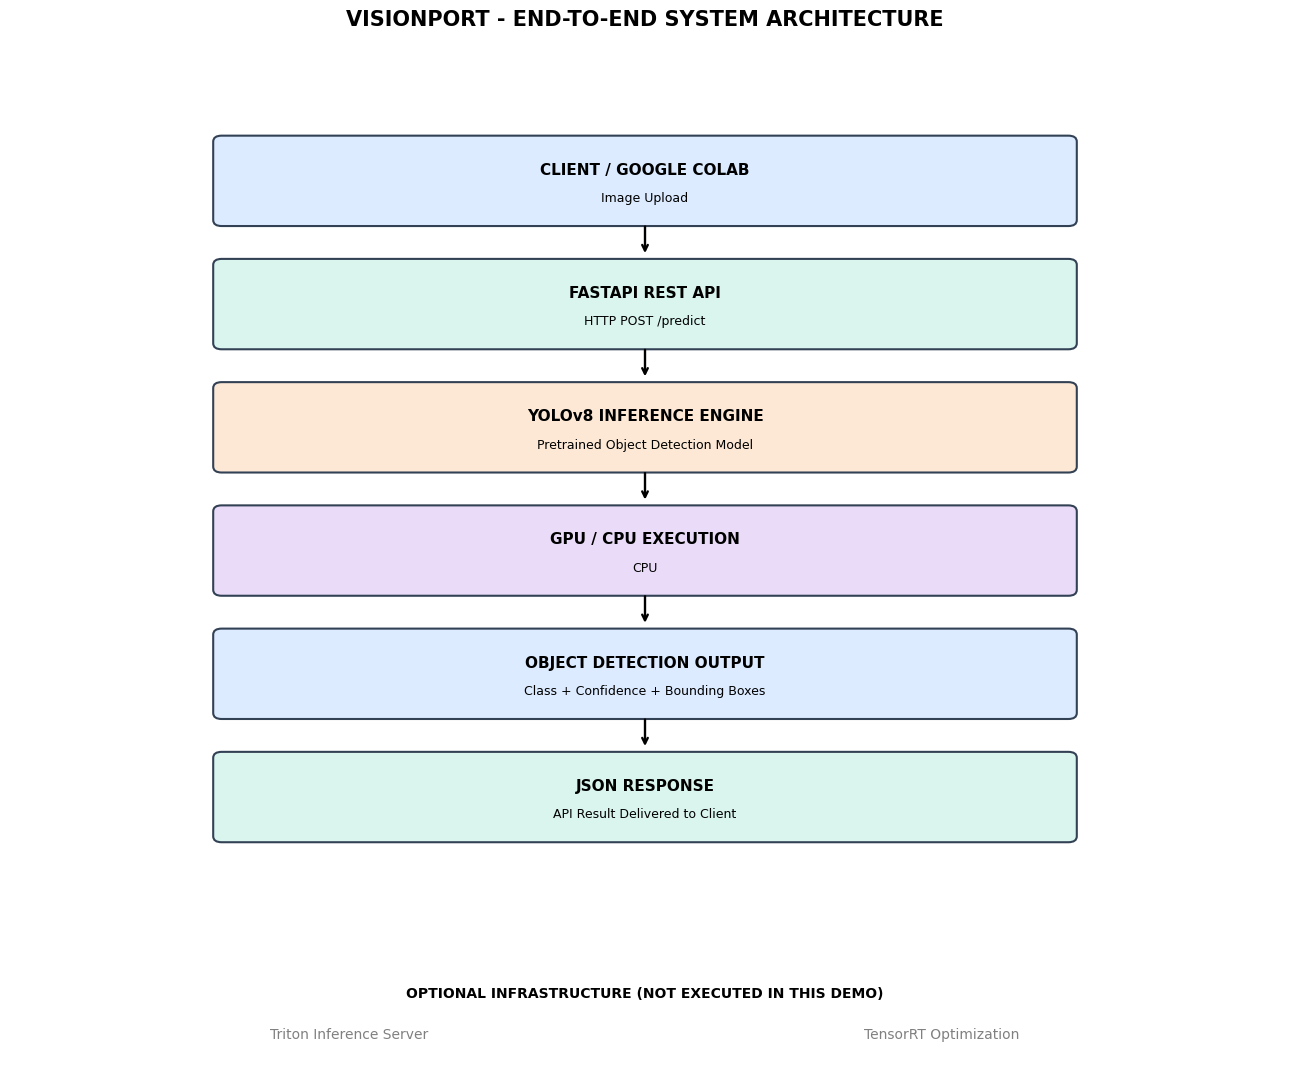


13. OBJECT CONFIDENCE ANALYSIS
-------------------------------------------------------


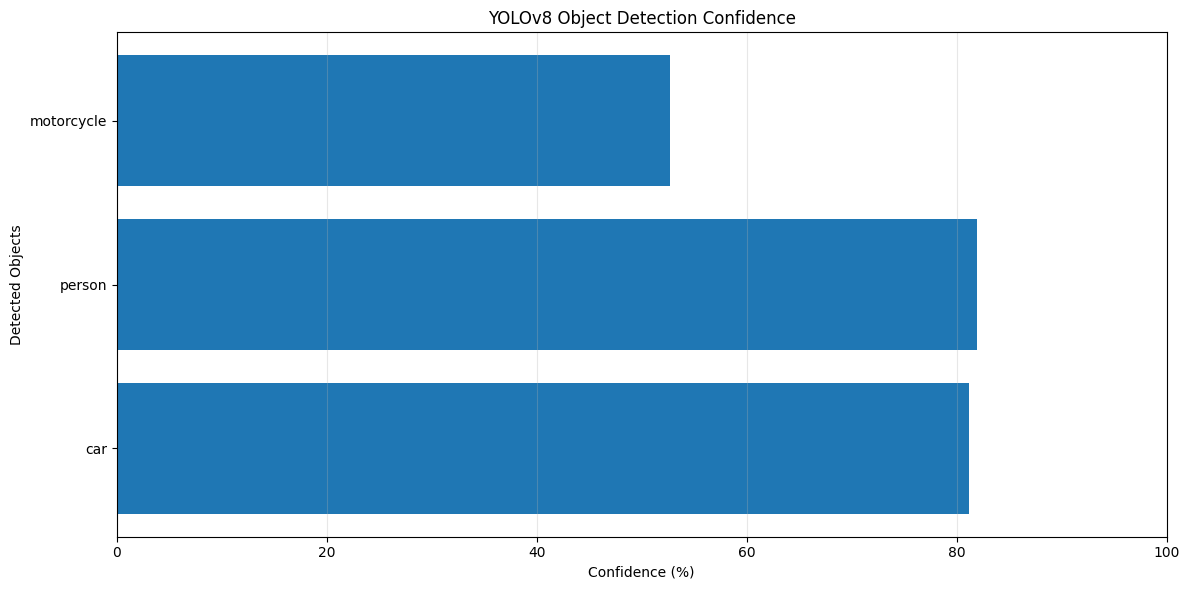


14. OBJECT CATEGORY ANALYSIS
-------------------------------------------------------
person: 15
car: 8
motorcycle: 1

15. SYSTEM PERFORMANCE ANALYSIS
-------------------------------------------------------


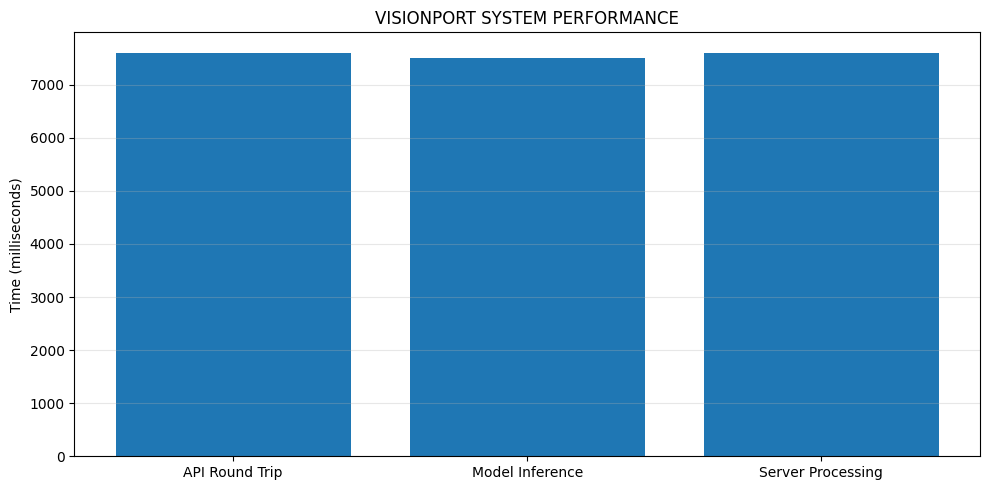


16. OUTPUT GENERATION
-------------------------------------------------------
Output Image Saved Successfully!
Filename: VisionPort_SKILL_2_Output.jpg


             VISIONPORT FINAL SYSTEM REPORT
Project Name             : VISIONPORT
Experiment               : SKILL_2
Architecture              : FastAPI + YOLOv8
Model                     : YOLOv8 Nano
Image Acquisition         : SUCCESS
Image Preprocessing       : SUCCESS
FastAPI Server            : RUNNING
HTTP POST Request         : SUCCESS
API Health Check          : SUCCESS
YOLOv8 Model              : LOADED
Object Detection          : COMPLETED
Bounding Box Generation   : COMPLETED
JSON Response             : RECEIVED
Output Visualization      : COMPLETED
Output Image Saving       : SUCCESS
----------------------------------------------------------------------
GPU Available             : False
Execution Hardware        : CPU
TensorRT Available        : False
Triton Client Installed   : False
Triton Server Running     : False
---

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


EXPERIMENT 2 COMPLETED SUCCESSFULLY!


In [1]:
# ============================================================
# VISIONPORT - SKILL-2
# END-TO-END DEEP LEARNING SYSTEM ARCHITECTURE
# FastAPI + YOLOv8 + GPU/CPU + Triton/TensorRT Readiness
# ============================================================


# 1. INSTALL DEPENDENCIES

!pip install -q ultralytics fastapi uvicorn python-multipart requests pillow


# 2. IMPORT LIBRARIES

import os
import time
import threading
import requests
import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

from ultralytics import YOLO
from fastapi import FastAPI, UploadFile, File, HTTPException
from PIL import Image, UnidentifiedImageError
from io import BytesIO
from collections import Counter
import uvicorn

from google.colab import files


print("=" * 70)
print("       VISIONPORT - END-TO-END SYSTEM ARCHITECTURE")
print("=" * 70)


# 3. CHECK HARDWARE AND SOFTWARE CONFIGURATION

print("\n1. SYSTEM CONFIGURATION")
print("-" * 55)

print("Python Version:", os.sys.version.split()[0])
print("PyTorch Version:", torch.__version__)

gpu_available = torch.cuda.is_available()

if gpu_available:

    gpu_name = torch.cuda.get_device_name(0)
    hardware = gpu_name
    device = "0"

else:

    gpu_name = "No NVIDIA GPU detected"
    hardware = "CPU"
    device = "cpu"


print("GPU Available:", gpu_available)
print("Hardware:", hardware)
print("Execution Device:", device)


# 4. CHECK TENSORRT AVAILABILITY

print("\n2. TENSORRT CONFIGURATION")
print("-" * 55)

try:

    import tensorrt as trt

    tensorrt_available = True
    trt_version = trt.__version__

except Exception:

    tensorrt_available = False
    trt_version = "Not installed"


print("TensorRT Available:", tensorrt_available)
print("TensorRT Version:", trt_version)


# 5. CHECK TRITON AVAILABILITY

print("\n3. TRITON CONFIGURATION")
print("-" * 55)

try:

    import tritonclient

    triton_client_available = True

except ImportError:

    triton_client_available = False


TRITON_URL = "http://127.0.0.1:8000"

try:

    triton_response = requests.get(
        TRITON_URL + "/v2/health/ready",
        timeout=2
    )

    triton_running = triton_response.status_code == 200

except requests.RequestException:

    triton_running = False


print("Triton Client Installed:", triton_client_available)
print("Triton Server Running:", triton_running)


# 6. UPLOAD INPUT IMAGE

print("\n4. IMAGE ACQUISITION")
print("-" * 55)

print("Upload a real photograph...")

uploaded = files.upload()

if not uploaded:

    raise ValueError("No image uploaded!")


image_path = list(uploaded.keys())[0]

print("Image Uploaded Successfully!")
print("Filename:", image_path)


# 7. LOAD YOLOv8 MODEL

print("\n5. YOLOv8 MODEL INITIALIZATION")
print("-" * 55)

model = YOLO("yolov8n.pt")

print("YOLOv8 Model Loaded Successfully!")
print("Model: YOLOv8 Nano")
print("Execution Device:", hardware)


# 8. CREATE FASTAPI APPLICATION

print("\n6. FASTAPI APPLICATION INITIALIZATION")
print("-" * 55)

app = FastAPI(

    title="VisionPort Inference API",

    description="End-to-End Deep Learning Object Detection API",

    version="2.0"

)


@app.get("/")
def home():

    return {

        "project": "VisionPort",

        "experiment": "SKILL_2",

        "status": "Running",

        "model": "YOLOv8 Nano",

        "hardware": hardware

    }


@app.get("/health")
def health():

    return {

        "api_status": "Healthy",

        "model_loaded": model is not None,

        "hardware": hardware,

        "gpu_available": gpu_available,

        "tensorrt_available": tensorrt_available,

        "triton_available": triton_running

    }


# 9. CREATE PREDICTION API

@app.post("/predict")
async def predict(file: UploadFile = File(...)):

    start_time = time.perf_counter()

    # Validate uploaded file

    if not file.content_type or not file.content_type.startswith("image/"):

        raise HTTPException(
            status_code=400,
            detail="Please upload a valid image."
        )

    content = await file.read()

    if len(content) == 0:

        raise HTTPException(
            status_code=400,
            detail="Uploaded file is empty."
        )

    if len(content) > 10 * 1024 * 1024:

        raise HTTPException(
            status_code=413,
            detail="Image size must be below 10 MB."
        )

    try:

        # Convert uploaded bytes into RGB image

        pil_image = Image.open(
            BytesIO(content)
        ).convert("RGB")

    except (UnidentifiedImageError, OSError):

        raise HTTPException(
            status_code=400,
            detail="Invalid or corrupted image."
        )

    # Perform YOLO inference

    inference_start = time.perf_counter()

    results = model.predict(

        source=pil_image,

        conf=0.25,

        imgsz=640,

        device=device,

        verbose=False

    )

    inference_time = (
        time.perf_counter() - inference_start
    ) * 1000

    # Extract detection information

    detections = []

    boxes = results[0].boxes

    if boxes is not None:

        for box in boxes:

            class_id = int(box.cls[0])

            confidence = float(box.conf[0])

            coordinates = [

                round(float(x), 2)

                for x in box.xyxy[0].tolist()

            ]

            detections.append({

                "object": model.names[class_id],

                "confidence": round(
                    confidence * 100, 2
                ),

                "bounding_box": coordinates

            })

    total_time = (
        time.perf_counter() - start_time
    ) * 1000

    return {

        "status": "success",

        "filename": file.filename,

        "model": "YOLOv8 Nano",

        "hardware": hardware,

        "total_objects": len(detections),

        "inference_time_ms": round(
            inference_time, 2
        ),

        "total_processing_time_ms": round(
            total_time, 2
        ),

        "detections": detections

    }


print("FastAPI Application Created Successfully!")


# 10. START FASTAPI SERVER

print("\n7. STARTING FASTAPI SERVER")
print("-" * 55)

API_HOST = "127.0.0.1"

# Use a different port from Triton's default HTTP port 8000.
API_PORT = 8001

server_errors = []


def start_server():

    try:

        uvicorn.run(

            app,

            host=API_HOST,

            port=API_PORT,

            log_level="error"

        )

    except Exception as e:

        server_errors.append(str(e))


server_thread = threading.Thread(

    target=start_server,

    daemon=True

)

server_thread.start()


# Wait until API becomes available

API_URL = f"http://{API_HOST}:{API_PORT}"

api_ready = False

for i in range(40):

    if server_errors:

        raise RuntimeError(
            "FastAPI startup failed: " + server_errors[0]
        )

    try:

        response = requests.get(
            API_URL + "/health",
            timeout=2
        )

        if response.status_code == 200:

            api_ready = True
            break

    except requests.RequestException:

        time.sleep(1)


if not api_ready:

    raise RuntimeError("FastAPI server failed to start!")


print("FastAPI Server Started Successfully!")

print("API Address:", API_URL)

print("Home Endpoint:", API_URL + "/")

print("Health Endpoint:", API_URL + "/health")

print("Prediction Endpoint:", API_URL + "/predict")

print("API Documentation:", API_URL + "/docs")


# 11. TEST API HEALTH

print("\n8. API HEALTH CHECK")
print("-" * 55)

health_response = requests.get(
    API_URL + "/health"
)

health_data = health_response.json()

print("API Status:", health_data["api_status"])

print("Model Loaded:", health_data["model_loaded"])

print("Hardware:", health_data["hardware"])


# 12. SEND IMAGE THROUGH HTTP POST REQUEST

print("\n9. HTTP POST IMAGE INFERENCE")
print("-" * 55)

api_start = time.perf_counter()

with open(image_path, "rb") as f:

    api_response = requests.post(

        API_URL + "/predict",

        files={

            "file": (

                os.path.basename(image_path),

                f,

                "image/jpeg"

            )

        },

        timeout=180

    )


api_elapsed = (
    time.perf_counter() - api_start
) * 1000


if api_response.status_code != 200:

    raise RuntimeError(
        "API Error: " + api_response.text
    )


output_data = api_response.json()


print("API Response Received Successfully!")

print("Status:", output_data["status"])

print("Filename:", output_data["filename"])

print("Total Objects:", output_data["total_objects"])

print(
    "Inference Time:",
    output_data["inference_time_ms"],
    "ms"
)

print(
    "Total Processing Time:",
    output_data["total_processing_time_ms"],
    "ms"
)


# 13. DISPLAY DETECTION RESULTS

print("\n10. OBJECT DETECTION RESULTS")
print("-" * 55)

detections = output_data["detections"]

if detections:

    for i, detection in enumerate(detections):

        print(f"\nObject {i + 1}")

        print("Name:", detection["object"])

        print(
            "Confidence:",
            detection["confidence"],
            "%"
        )

        print(
            "Bounding Box:",
            detection["bounding_box"]
        )

else:

    print("No objects detected.")


# 14. GENERATE DETECTED IMAGE

print("\n11. DETECTION VISUALIZATION")
print("-" * 55)

original = cv2.imread(image_path)

if original is None:

    raise ValueError("Cannot read original image!")

original_rgb = cv2.cvtColor(
    original,
    cv2.COLOR_BGR2RGB
)


# Run inference for annotated image

visual_results = model.predict(

    source=original_rgb,

    conf=0.25,

    imgsz=640,

    device=device,

    verbose=False

)


detected_image = visual_results[0].plot()

detected_image = cv2.cvtColor(

    detected_image,

    cv2.COLOR_BGR2RGB

)


# Display original and detected images

plt.figure(figsize=(16, 7))

plt.subplot(1, 2, 1)

plt.imshow(original_rgb)

plt.title(
    "Client Input Image",
    fontsize=14
)

plt.axis("off")


plt.subplot(1, 2, 2)

plt.imshow(detected_image)

plt.title(
    "VisionPort API - Detected Objects",
    fontsize=14
)

plt.axis("off")

plt.tight_layout()

plt.show()


# 15. VISUALIZE SYSTEM ARCHITECTURE

print("\n12. SYSTEM ARCHITECTURE VISUALIZATION")
print("-" * 55)


fig, ax = plt.subplots(figsize=(13, 11))

ax.set_xlim(0, 12)

ax.set_ylim(0, 14)

ax.axis("off")


architecture = [

    ("CLIENT / GOOGLE COLAB",
     "Image Upload"),

    ("FASTAPI REST API",
     "HTTP POST /predict"),

    ("YOLOv8 INFERENCE ENGINE",
     "Pretrained Object Detection Model"),

    ("GPU / CPU EXECUTION",
     hardware),

    ("OBJECT DETECTION OUTPUT",
     "Class + Confidence + Bounding Boxes"),

    ("JSON RESPONSE",
     "API Result Delivered to Client")

]


colors = [

    "#DCEBFF",

    "#D9F5EE",

    "#FCE8D5",

    "#EADCF8",

    "#DCEBFF",

    "#D9F5EE"

]


for i, (title, subtitle) in enumerate(architecture):

    y = 11.5 - i * 1.65

    rect = patches.FancyBboxPatch(

        (2, y),

        8,

        1.05,

        boxstyle="round,pad=0.08",

        facecolor=colors[i],

        edgecolor="#334155",

        linewidth=1.5

    )

    ax.add_patch(rect)

    ax.text(

        6,

        y + 0.68,

        title,

        ha="center",

        va="center",

        fontsize=11,

        fontweight="bold"

    )

    ax.text(

        6,

        y + 0.30,

        subtitle,

        ha="center",

        va="center",

        fontsize=9

    )

    if i < len(architecture) - 1:

        ax.annotate(

            "",

            xy=(6, y - 0.48),

            xytext=(6, y - 0.05),

            arrowprops=dict(
                arrowstyle="->",
                lw=1.7
            )

        )


# Optional infrastructure components

ax.text(

    6,

    1.1,

    "OPTIONAL INFRASTRUCTURE (NOT EXECUTED IN THIS DEMO)",

    ha="center",

    fontsize=10,

    fontweight="bold"

)

ax.text(

    3.2,

    0.55,

    "Triton Inference Server",

    ha="center",

    fontsize=10,

    color="gray"

)

ax.text(

    8.8,

    0.55,

    "TensorRT Optimization",

    ha="center",

    fontsize=10,

    color="gray"

)


plt.title(

    "VISIONPORT - END-TO-END SYSTEM ARCHITECTURE",

    fontsize=15,

    fontweight="bold"

)

plt.tight_layout()

plt.show()


# 16. OBJECT CONFIDENCE GRAPH

print("\n13. OBJECT CONFIDENCE ANALYSIS")
print("-" * 55)


if detections:

    object_names = [

        d["object"] for d in detections

    ]

    confidence = [

        d["confidence"] for d in detections

    ]


    plt.figure(figsize=(12, 6))

    plt.barh(

        object_names[::-1],

        confidence[::-1]

    )

    plt.xlabel("Confidence (%)")

    plt.ylabel("Detected Objects")

    plt.title(
        "YOLOv8 Object Detection Confidence"
    )

    plt.xlim(0, 100)

    plt.grid(
        axis="x",
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


else:

    print("Confidence graph unavailable: no detections.")


# 17. OBJECT CATEGORY SUMMARY

print("\n14. OBJECT CATEGORY ANALYSIS")
print("-" * 55)


if detections:

    counts = Counter(

        d["object"] for d in detections

    )

    for name, count in counts.items():

        print(f"{name}: {count}")

else:

    print("No object categories detected.")


# 18. SYSTEM PERFORMANCE GRAPH

print("\n15. SYSTEM PERFORMANCE ANALYSIS")
print("-" * 55)


metrics = {

    "API Round Trip": api_elapsed,

    "Model Inference": output_data["inference_time_ms"],

    "Server Processing": output_data[
        "total_processing_time_ms"
    ]

}


plt.figure(figsize=(10, 5))

plt.bar(

    metrics.keys(),

    metrics.values()

)

plt.ylabel("Time (milliseconds)")

plt.title("VISIONPORT SYSTEM PERFORMANCE")

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()


# 19. SAVE DETECTED IMAGE

print("\n16. OUTPUT GENERATION")
print("-" * 55)


output_path = "VisionPort_SKILL_2_Output.jpg"


success = cv2.imwrite(

    output_path,

    cv2.cvtColor(
        detected_image,
        cv2.COLOR_RGB2BGR
    )

)


if not success:

    raise IOError("Output image saving failed!")


print("Output Image Saved Successfully!")

print("Filename:", output_path)


# 20. FINAL SYSTEM REPORT

print("\n")

print("=" * 70)

print("             VISIONPORT FINAL SYSTEM REPORT")

print("=" * 70)


print("Project Name             : VISIONPORT")

print("Experiment               : SKILL_2")

print("Architecture              : FastAPI + YOLOv8")

print("Model                     : YOLOv8 Nano")

print("Image Acquisition         : SUCCESS")

print("Image Preprocessing       : SUCCESS")

print("FastAPI Server            : RUNNING")

print("HTTP POST Request         : SUCCESS")

print("API Health Check          : SUCCESS")

print("YOLOv8 Model              : LOADED")

print("Object Detection          : COMPLETED")

print("Bounding Box Generation   : COMPLETED")

print("JSON Response             : RECEIVED")

print("Output Visualization      : COMPLETED")

print("Output Image Saving       : SUCCESS")

print("-" * 70)

print("GPU Available             :", gpu_available)

print("Execution Hardware        :", hardware)

print("TensorRT Available        :", tensorrt_available)

print("Triton Client Installed   :", triton_client_available)

print("Triton Server Running     :", triton_running)

print("-" * 70)

print("Total Objects Detected    :", len(detections))

print(
    "Inference Time            :",
    output_data["inference_time_ms"],
    "ms"
)

print(
    "API Round Trip Time       :",
    round(api_elapsed, 2),
    "ms"
)

print("=" * 70)

print("VISIONPORT SKILL_2 PIPELINE COMPLETED!")

print("=" * 70)


# 21. DOWNLOAD OUTPUT IMAGE

print("\nDownloading Detection Output...")

files.download(output_path)

print("\nEXPERIMENT 2 COMPLETED SUCCESSFULLY!")